# Question 2 — Motion or Memory?

Eight prescribed runs; seed-0 figures; all performance numbers use the complete test split. Cached completed runs are loaded on re-execution. The accompanying `q2_experiments.py` and `q2_results.py` contain the implementation used below.

In [1]:
from pathlib import Path
import torch
from q2_experiments import *
from q2_results import baseline_figures, final_figures, tables
torch.set_num_threads(4)
assert torch.xpu.is_available(), 'Select the Intel XPU kernel.'
print(torch.__version__, torch.xpu.get_device_name(0))
ds = load_data()
checks()
if not (ROOT/'figures'/'figure1.png').exists(): flow_figure(ds)

2.14.1+xpu Intel(R) Arc(TM) 140T GPU (23GB)


[['a', 0, True], ['b', 0, True], ['c', 0, True], ['d', [7, 10, 43]], ['e', [7, 43, 10]], ['1x', [1, 2, 3, 4, 5], [6, 7, 8, 9, 10]], ['2x', [1, 3, 5, 7, 9], [11, 13, 15, 17, 19]], ['3x', [1, 4, 7, 10, 13], [16, 19]]]


## Setup and Table 1

Load `torchvision.datasets.MovingMNIST(split=None, download=True)`. Split by video index: 0–7999 training, 8000–8999 validation, 9000–9999 test. Inputs are float32 intensities divided by 255. Every scored model result uses all 1,000 test videos at $t=1$. The validation set is reserved and was not needed for design selection: D was fixed before its training. No optional D+B model is trained.

**Table 1.** Transformation and window checks (the same functions used in all experiments).

| Check | Expected | Yours |
|---|---|---|
| (a) $\max\lvert M(M(x))-x\rvert$ | 0; equal True | 0; `torch.equal=True` |
| (b) $\max\lvert R^4(x)-x\rvert$ | 0; equal True | 0; `torch.equal=True` |
| (c) $\max\lvert MRM(x)-R^{-1}(x)\rvert$ | 0; equal True | 0; `torch.equal=True` |
| (d) bright pixel of $M(p)$, zero-based (frame,row,column) | (7,10,43) | (7,10,43) |
| (e) bright pixel of $R(p)$, zero-based (frame,row,column) | (7,43,10) | (7,43,10) |
| (f) 1x input / valid target frames | 1–5 / 6–10 | 1–5 / 6–10 |
| (g) 2x input / valid target frames | 1,3,5,7,9 / 11,13,15,17,19 | 1,3,5,7,9 / 11,13,15,17,19 |
| (h) 3x input / valid target frames | 1,4,7,10,13 / 16,19 | 1,4,7,10,13 / 16,19 |


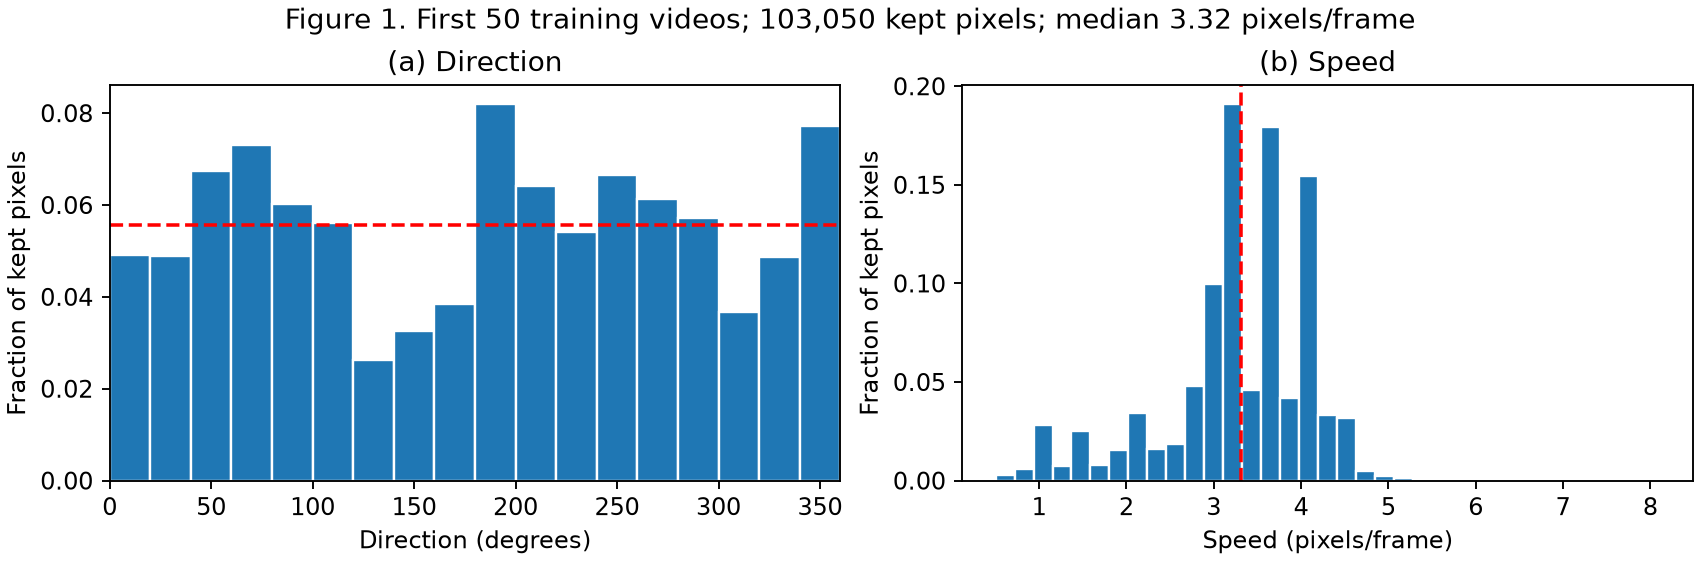

Figure 1. Farneback flow from the first 50 training videos, all 950 consecutive frame pairs; 103,050 pixels retained. Median speed 3.32 pixels/frame. Both histograms show fractions of retained pixels; direction reference 1/18 and speed median are marked.

### Q2.1

Figure 1(a) covers all direction bins, although it is not perfectly uniform. Mirroring maps $\theta$ to $180^\circ-\theta$ modulo $360^\circ$; anticlockwise rotation adds $90^\circ$. Such rearrangements broadly preserve the occupied directions, so mirrored and rotated trajectories should already be familiar as motion types, even though the small sample is not exactly invariant. The 3.32-pixel/frame median in Figure 1(b) corresponds approximately to 6.64 at 2x and 9.95 at 3x, away from bounce-induced displacement cancellation. This is an optical-flow proxy, not digit-centre ground truth. Overlap can create erroneous flow and the intersection-intensity mask preferentially retains shared foreground, potentially biasing both histograms and the median; repeated pixels within a trajectory are strongly correlated. The plots support diverse directions, but cannot rule out quantitative bias or prove exact symmetry of the complete training distribution.

### Q2.2

Mirror and rotation change digit appearance. With an isotropic direction distribution they leave motion statistics unchanged, although each individual velocity vector is transformed; in this finite sample the direction histogram is only approximately symmetric, so its frequencies can change somewhat, while speed magnitudes are preserved. They therefore chiefly probe dependence on unfamiliar appearances, with finite directional imbalance as a caveat. Speed-up preserves each sampled digit's spatial appearance while changing temporal displacement, observed bounce/overlap timing and motion statistics. Together these are controlled interventions on appearance versus temporal motion, rather than a guarantee that the data distribution is invariant.

## Baseline and training protocol

Fold each frame with `pixel_unshuffle(4)`: $1\times64\times64\to16\times16\times16$. Both recurrent layers have 64 hidden channels, 3-by-3 gates, padding 1 and biases. The second takes the first layer's new hidden state. With no peepholes,

$$[i,f,o,g]=\operatorname{Conv}_{3\times3}([u_\tau,h_{\tau-1}]),\quad c_\tau=\sigma(f)\odot c_{\tau-1}+\sigma(i)\odot\tanh(g),\quad h_\tau=\sigma(o)\odot\tanh(c_\tau).$$

The output is $\widehat x_{\tau+1}=\sigma(\operatorname{PixelShuffle}_4(\operatorname{Conv}_{1\times1}(h^{(2)}_\tau)))$. All states start at zero per video. Steps 1–5 consume the five observed frames; steps 6–9 consume the previous prediction with its gradient attached. Only outputs at steps 5–9 are scored. No normalization, dropout, residual or extra layers are added to A–C. Gate parameters are $256(16+64)9+256=184576$ and $256(64+64)9+256=295168$; the head has $16\cdot64+16=1040$, giving **480,784** parameters.

Every learned model uses seeds 0 and 1, Adam with learning rate $10^{-3}$, batch size 32, 30 epochs, and final-epoch weights. Each epoch shuffles 8,000 videos and samples one window per video. A/B draw $t\in[1,11]$ at 1x; C/D draw $k$ uniformly from $\{1,2,3\}$, then $t$ uniformly from $[1,14]$, $[1,8]$ or $[1,2]$. B draws one of eight spatial symmetries uniformly, identically for input and target. C/D have no symmetry augmentation. All models generate five frames even when only two targets exist. The loss is

$$\mathcal L=\frac1B\sum_{b=1}^B\frac{\sum_{h=1}^5m_{bh}\left(\frac1{4096}\sum_p(\widehat Y_{bhp}-Y_{bhp})^2\right)}{\sum_{h=1}^5m_{bh}}.$$

Hardware: Intel Arc 140T GPU (23 GB reported shared device memory), PyTorch 2.14.1+xpu and torchvision 0.29.1+xpu. Inputs/weights/loss are float32, with XPU bfloat16 autocast and channels-last convolutions. Training uses `torch.compile`; A seed 0's first ten completed epochs used eager execution, and subsequent epochs use compilation. Saved timings retain actual completed-epoch wall time, including compilation when encountered; the excluded preliminary float32 run contributes no weights or timing. Other learned runs use compilation throughout. Evaluation uses the same model computations in eager mode, `eval()` and `no_grad()`. Each inference batch is already on XPU when its synchronized timer starts. Dataset download is excluded. No CPU training/inference fallback and no NPU conversion is used.

In [2]:
# Implementation: q2_experiments.Cell, Forecaster, masked_mse and train.
assert sum(p.numel() for p in Forecaster().parameters()) == 480784
for seed in (0,1): train(ds,'A',seed)

In [3]:
# Cached outputs were originally computed only after the Q2.5 commit.
assert (ROOT/'Q2_5_preregistered.md').exists()
for name in ('Blank','Copy-last','A'):
    for seed in ((0,) if name in ('Blank','Copy-last') else (0,1)):
        evaluate(ds,name,seed)
if not (ROOT/'figures'/'figure5.png').exists(): baseline_figures(ds)
tables(False)

**Table 2.** Normal-speed baseline accuracy and parameters.

| Model | MSE1 | MSE2 | MSE3 | MSE4 | MSE5 | E5 | parameters |
|---|---:|---:|---:|---:|---:|---:|---:|
| A | 0.0169 (0.0178, 0.0160) | 0.0203 (0.0213, 0.0193) | 0.0227 (0.0238, 0.0215) | 0.0245 (0.0256, 0.0233) | 0.0261 (0.0273, 0.0250) | 0.0221 (0.0232, 0.0210) | 480784 (480784, 480784) |
| Blank | 0.0426 | 0.0426 | 0.0426 | 0.0425 | 0.0425 | 0.0426 | 0 |
| Copy-last | 0.0492 | 0.0604 | 0.0669 | 0.0708 | 0.0732 | 0.0641 | 0 |

Learned entries: mean (seed 0, seed 1). Errors are pixel MSE on 1,000 test videos. Timing columns are seconds; inference excludes host-to-device transfer and includes XPU synchronization.


![Figure 2. Model A seed 0 on test videos [9000, 9001, 9002]; input frames 1–5 are repeated for context, with predicted versus true frames 6–10. Video 9000 contains overlapping digits in the displayed truth (confirmed visually).](attachment:figure2.png)

Figure 2. Model A seed 0 on test videos [9000, 9001, 9002]; input frames 1–5 are repeated for context, with predicted versus true frames 6–10. Video 9000 contains overlapping digits in the displayed truth (confirmed visually).
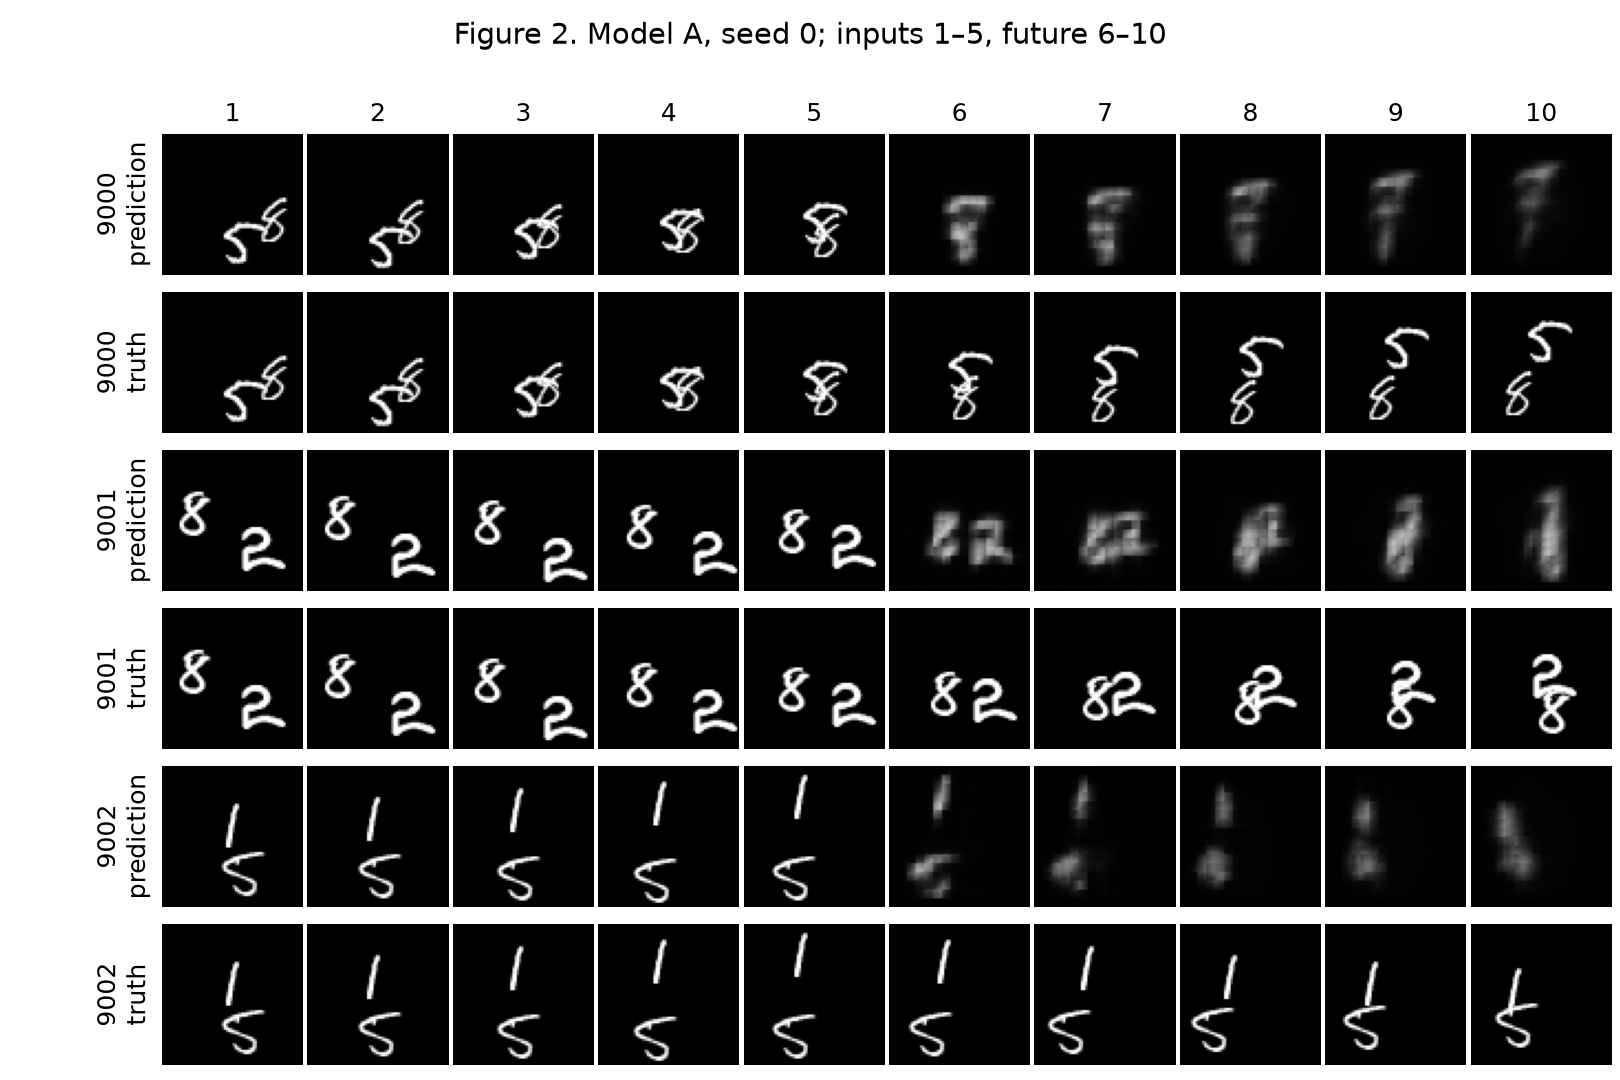

### Q2.3

One folded-cell displacement corresponds to four original pixels; patch width adds nothing under the stated convention. Within one update, input and previous layer-1 hidden-state paths can traverse the layer-1 3-by-3 gate and then the layer-2 3-by-3 gate. Their maximal offset is two folded cells along either axis, or **8 original pixels per axis**. The previous layer-2 state traverses only its own 3-by-3 gate (4 pixels per axis), and cell-state carry is pointwise. The head and shuffle do not expand reach. Thus the longest path has square support with $L_\infty$ radius 8; its greatest centre-to-centre Euclidean displacement is $8\sqrt2\approx11.3$ pixels at a corner. A diagonal maximum does not give an 11.3-pixel radius in every direction. Earlier recurrent steps enlarge total history support, but cannot be counted as additional layers in this one-step quantity.

### Q2.4

Table 2 gives model A $E^{(5)}=0.0221$ versus Blank 0.0426 and Copy-last 0.0641; it is better than both references. A's MSE increases at every forecast horizon, from 0.0169 at $h=1$ to 0.0261 at $h=5$. Figure 2 shows the limits behind the MSE improvement. In test video 9000, the 5 and 8 overlap in the input and separate in the true future, whereas A produces a blurred vertical structure instead of recovering both digit identities. In video 9001, the approaching 8 and 2 also merge into diffuse foreground in the predictions. Video 9002 shows that even without initial overlap, the thin 1 and the 5 lose their shapes over the rollout. The model captures some position changes while increasingly averaging uncertain appearances and tracks.

### Q2.5 — preserved pre-experiment prediction

I expect model A to fail exact mirror and rotation consistency, with rotation likely harder because it changes digit appearance more, even though many transformed directions already occur in training. Its longest within-step path crosses two 3-by-3 neighbourhoods on a grid spaced four original pixels apart: reach is 8 pixels along an axis (8 sqrt(2) on a diagonal). Figure 1's measured median speed is 3.32 pixels/frame, so 2x is about 6.64 and 3x about 9.95; I expect substantial degradation at 3x and some at 2x, while recognising that this median and an architectural path bound do not determine a sharp failure threshold.

## Testing the baseline

$$C_T=\operatorname{MSE}(f(TX),T f(X)),\qquad E_T=\operatorname{MSE}(f(TX),TY).$$

Both average pixels, five horizons and all 1,000 test videos at 1x.

**Table 3.** Mirror/rotation consistency and transformed correctness at 1x.

| Model | E5 | CM | EM | CR | ER |
|---|---:|---:|---:|---:|---:|
| A | 0.0221 (0.0232, 0.0210) | 0.00174 (0.00149, 0.00199) | 0.0227 (0.0236, 0.0218) | 0.00303 (0.00278, 0.00328) | 0.0238 (0.0247, 0.0230) |
| Blank | 0.0426 | 0.00 | 0.0426 | 0.00 | 0.0426 |
| Copy-last | 0.0641 | 0.00 | 0.0641 | 0.00 | 0.0641 |

Learned entries: mean (seed 0, seed 1). Errors are pixel MSE on 1,000 test videos. Timing columns are seconds; inference excludes host-to-device transfer and includes XPU synchronization.


![Figure 3. Seed-0 model A: the two largest per-video mirror gaps (videos [9636, 9490]) and rotation gaps (videos [9917, 9036]). Each panel has the four specified rows and ten frame columns. GIFs: `gifs/figure3_m1.gif`, `gifs/figure3_m2.gif`, `gifs/figure3_r1.gif`, `gifs/figure3_r2.gif`; each keeps the same four rows and advances through five forecast horizons. Video indices refer to the original dataset.](attachment:figure3.png)

Figure 3. Seed-0 model A: the two largest per-video mirror gaps (videos [9636, 9490]) and rotation gaps (videos [9917, 9036]). Each panel has the four specified rows and ten frame columns. GIFs: `gifs/figure3_m1.gif`, `gifs/figure3_m2.gif`, `gifs/figure3_r1.gif`, `gifs/figure3_r2.gif`; each keeps the same four rows and advances through five forecast horizons. Video indices refer to the original dataset.


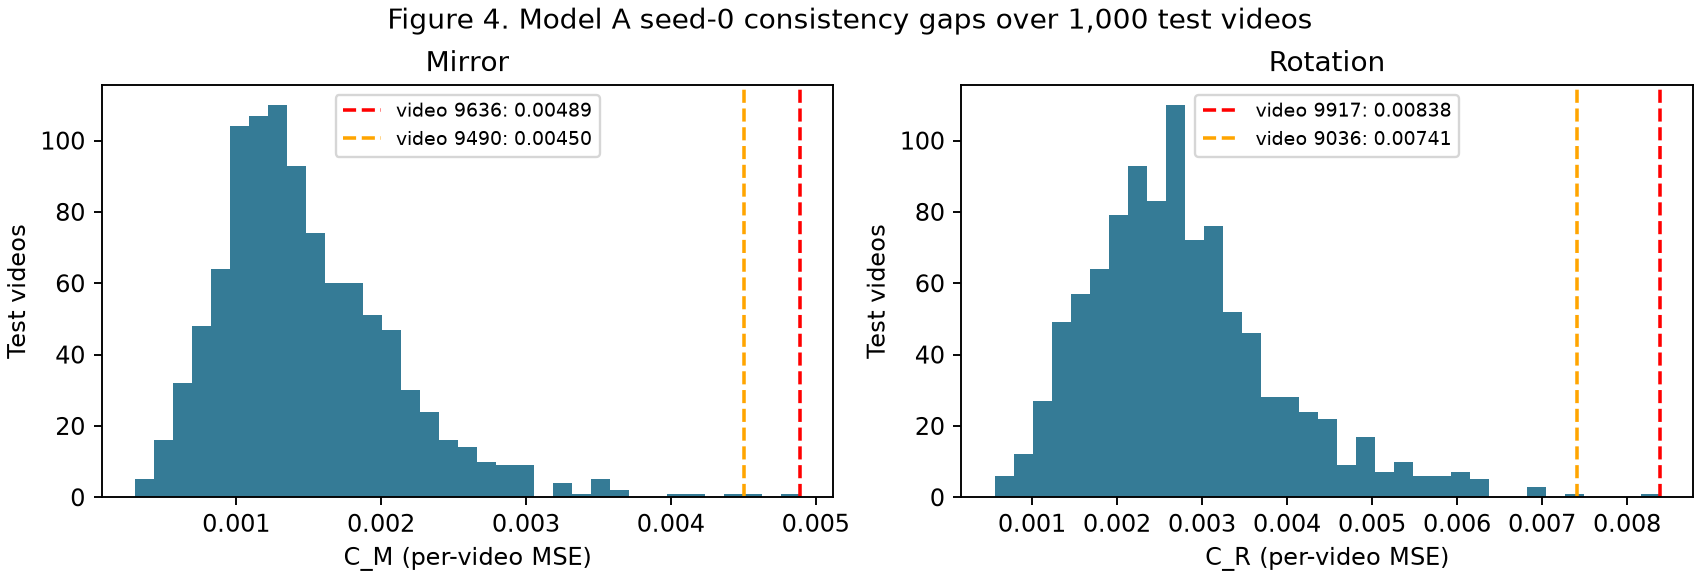

Figure 4. Per-video mirror/rotation gap distributions for model A seed 0 over the complete test set. The Figure 3 videos are marked with their indices and gap values.
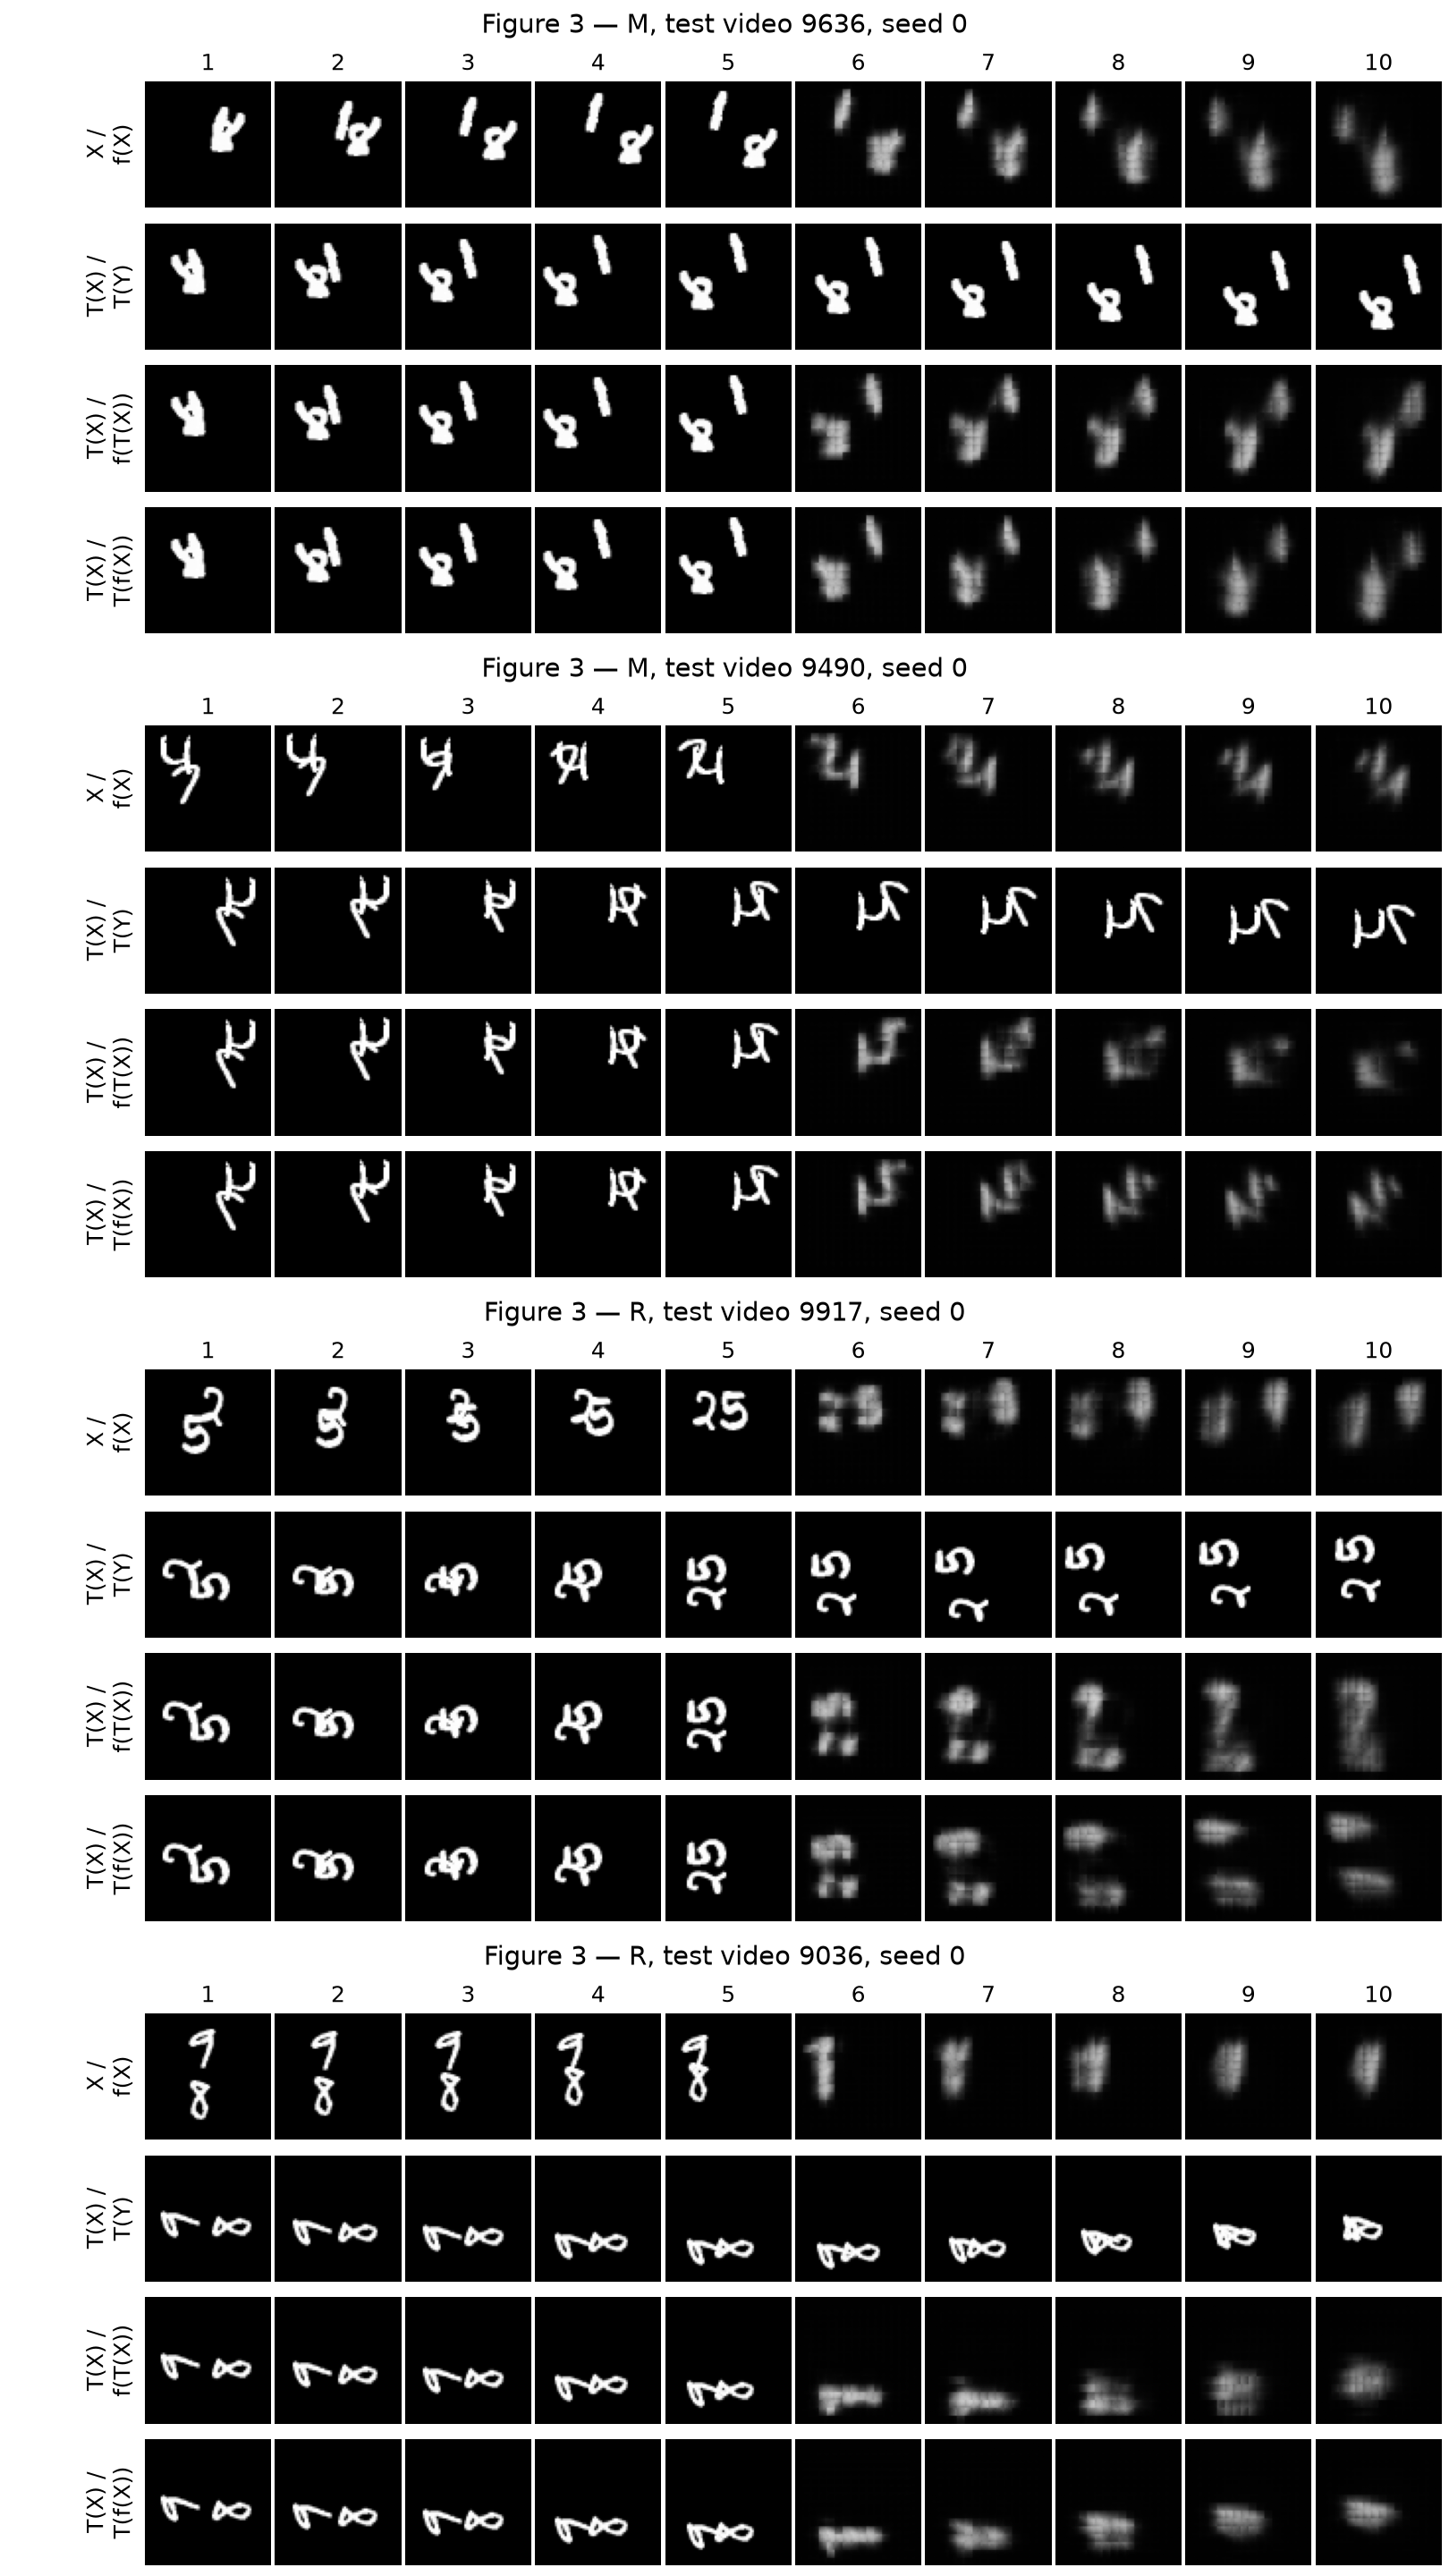

### Q2.6

Blank and Copy-last commute exactly with pixel permutations: $0=T0$ and copying the last transformed input equals transforming the copied last input. Their consistency gaps are zero despite substantial transformed error in Table 3. $C_T$ measures agreement between two prediction routes, not agreement with the real future. Reporting $E_T$ alongside it prevents a perfectly symmetric but useless predictor from appearing successful.

### Q2.7

Consider the rotation panel for test video 9917 in Figure 3 (model A, seed 0, 1x). By forecast horizons 4-5, predicting directly from the rotated inputs (row 3) produces a dominant vertical blurred mass with a faint lower remnant. Rotating the original prediction (row 4) instead leaves two visibly separated horizontal bands. The true future in row 2 retains two recognizable rotated digits. Rotation therefore changes whether A maintains two separate digit tracks and how their shapes evolve; both routes are also visibly inaccurate against the truth.

### Q2.8

For model A at 1x, Table 3 gives mirror $E_M=0.0227$ and rotation $E_R=0.0238$; rotation is harder by transformed forecast MSE. The corresponding gaps are $C_M=0.00174$ and $C_R=0.00303$; a larger consistency gap is not by itself greater forecast error. Figure 1 shows broad directional support and Q2.2 identifies a stronger appearance change under rotation, so appearance dependence is a plausible explanation for a rotation penalty. These results alone do not prove exclusive appearance causation: finite direction imbalance, spatial folding, padding and anisotropic learned filters can also contribute.

**Table 4.** Speed tests; E(2) uses only the first two forecast horizons.

| Model | E2_1 | E2_2 | E2_3 | E5 | E5_2 |
|---|---:|---:|---:|---:|---:|
| A | 0.0186 (0.0195, 0.0177) | 0.0442 (0.0432, 0.0453) | 0.0507 (0.0504, 0.0510) | 0.0221 (0.0232, 0.0210) | 0.0487 (0.0476, 0.0498) |
| Copy-last | 0.0548 | 0.0661 | 0.0703 | 0.0641 | 0.0719 |

Learned entries: mean (seed 0, seed 1). Errors are pixel MSE on 1,000 test videos. Timing columns are seconds; inference excludes host-to-device transfer and includes XPU synchronization.


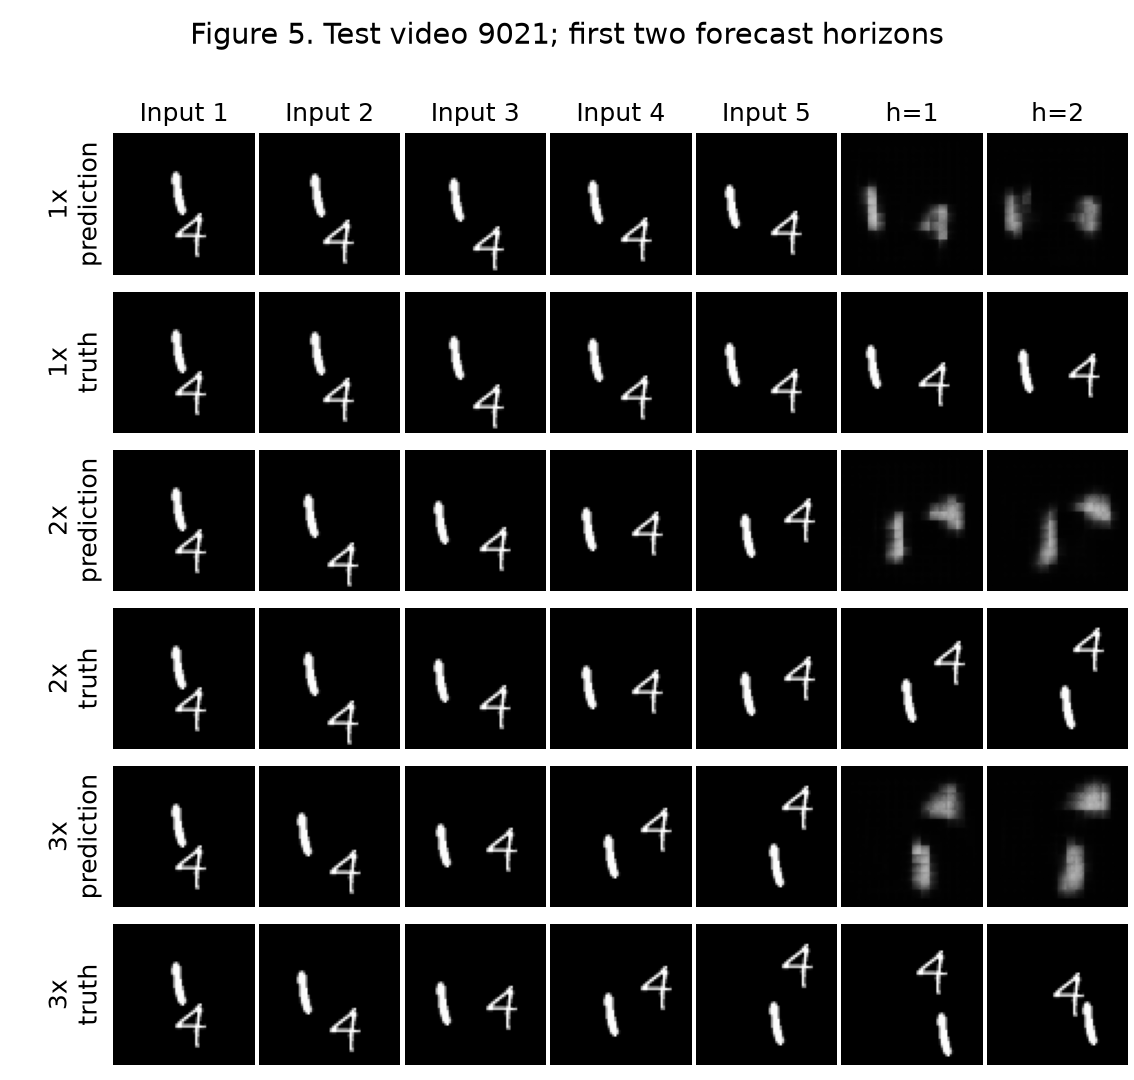

Figure 5. Model A seed 0 on the same non-overlapping test video 9021 at 1x, 2x and 3x. Five inputs and only the first two predicted/true forecast horizons are displayed for fair comparison. The displayed true frames were checked for separated digits.

### Q2.9

Table 4 gives A's $E^{(2)}$ at 1x/2x/3x as 0.0186, 0.0442, 0.0507; Copy-last gives 0.0548, 0.0661, 0.0703. A degrades markedly already at 2x and worsens further at 3x, so the evidence does not support a clean failure threshold only at 3x. In Figure 5, video 9021's 1 already becomes blurry at 1x; at 2x its predicted position lags the lower true future position. At 3x the predicted 4 stays near the upper-right while the real 4 moves down after its boundary interaction, and the 1's diffuse prediction fails to follow the true lower-right path. These stalls and lagging positions suggest underestimated motion and weak bounce handling; blur suggests averaging uncertain trajectories and appearance. There is no clear duplicated digit in this selected panel, so duplication is not claimed. The reach estimate is a spatial path bound rather than a sharp maximum trackable speed: vector direction, broad digit support, hidden velocity estimates from earlier frames, wall bounces and autoregressive error accumulation all matter. The flow median cannot predict the fastest individual digit, and 8 pixels per axis must not be confused with an isotropic Euclidean bound.

### Q2.10

A alone cannot separate unfamiliar fast motion from limited reach: increasing speed changes both displacement and training-distribution familiarity. Train C on the stated speed mixture with A's unchanged architecture, then compare it with D trained on the identical mixture using greater reach. Evaluate on the same test videos only after fixing designs; compare validation candidates if design selection is needed. C versus A tests data exposure, while D versus C tests the architectural intervention under equal data and training budget. Improvement supports these explanations but is not a proof of a hard physical speed cutoff, because dilation also changes inductive bias and optimization.

## What can data fix?

### Q2.11 — preserved prediction committed before B–D training

I expect B's symmetry augmentation to reduce A's mirror/rotation inconsistency and transformed error, but it cannot guarantee exact equivariance or expand architectural reach. I expect C's speed augmentation to improve faster-motion accuracy, while some 3x errors may remain because its reach is unchanged. I expect D's larger reach to improve those residual fast-motion errors relative to C, but neither speed-trained model is guaranteed to fix appearance sensitivity without symmetry augmentation or wrapping.

In [4]:
# Q2.11 was committed before the first B-D training run.
assert (ROOT/'Q2_11_preregistered.md').exists()
for name in ('B','C','D'):
    for seed in (0,1): train(ds,name,seed)
for name in ('B','C','D'):
    for seed in (0,1): evaluate(ds,name,seed)

**Table 5.** Models A–D: accuracy, consistency, parameters and timing.

| Model | E5 | CM | EM | CR | ER | E2_1 | E2_2 | E2_3 | parameters | train | inference |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| A | 0.0221 (0.0232, 0.0210) | 0.00174 (0.00149, 0.00199) | 0.0227 (0.0236, 0.0218) | 0.00303 (0.00278, 0.00328) | 0.0238 (0.0247, 0.0230) | 0.0186 (0.0195, 0.0177) | 0.0442 (0.0432, 0.0453) | 0.0507 (0.0504, 0.0510) | 480784 (480784, 480784) | 33.4 (38.0, 28.8) | 2.70 (3.96, 1.44) |
| B | 0.0229 (0.0235, 0.0224) | 0.00103 (9.67e-04, 0.00108) | 0.0229 (0.0234, 0.0223) | 0.00132 (0.00124, 0.00141) | 0.0229 (0.0234, 0.0223) | 0.0191 (0.0197, 0.0186) | 0.0450 (0.0443, 0.0456) | 0.0522 (0.0519, 0.0524) | 480784 (480784, 480784) | 31.8 (34.1, 29.5) | 2.32 (3.53, 1.11) |
| C | 0.0267 (0.0272, 0.0261) | 0.00153 (0.00137, 0.00169) | 0.0269 (0.0275, 0.0264) | 0.00270 (0.00247, 0.00293) | 0.0279 (0.0284, 0.0273) | 0.0227 (0.0230, 0.0225) | 0.0287 (0.0289, 0.0285) | 0.0334 (0.0336, 0.0332) | 480784 (480784, 480784) | 28.0 (25.0, 31.1) | 1.29 (1.32, 1.27) |
| D | 0.0302 (0.0301, 0.0302) | 4.24e-04 (3.85e-04, 4.62e-04) | 0.0302 (0.0302, 0.0303) | 7.70e-04 (7.97e-04, 7.44e-04) | 0.0306 (0.0306, 0.0306) | 0.0280 (0.0279, 0.0280) | 0.0310 (0.0309, 0.0311) | 0.0341 (0.0341, 0.0341) | 480784 (480784, 480784) | 29.6 (30.8, 28.3) | 2.07 (2.77, 1.38) |

Learned entries: mean (seed 0, seed 1). Errors are pixel MSE on 1,000 test videos. Timing columns are seconds; inference excludes host-to-device transfer and includes XPU synchronization.

### Q2.12

D retains layer 1's dilation 1 and changes only layer 2's 3-by-3 gate convolution to dilation 3 with padding 3. Hidden widths, biases, patch size, head, zero states and nine-step feedback rollout remain unchanged; it contains no attention. A longest within-step path crosses radii 1 and 3 on the folded grid, giving **16 original pixels per axis** ($L_\infty$ radius 16; Euclidean corner displacement $16\sqrt2\approx22.6$). The previous layer-2 state alone reaches 12 pixels per axis. Combined offsets $\{-1,0,1\}+\{-3,0,3\}=\{-4,-3,\ldots,4\}$ cover intermediate folded cells as well. D has exactly 480,784 parameters, below the 721,176 limit, since dilation changes spacing rather than weight count. No test performance was used to select D.

### Q2.13

The transformation failures have mixed evidence for an **appearance** explanation: A to B changes only symmetry augmentation, and Table 5 changes $E_M$ from 0.0227 to 0.0229, $E_R$ from 0.0238 to 0.0229, $C_M$ from 0.00174 to 0.00103, and $C_R$ from 0.00303 to 0.00132. B reduces both gaps and improves rotation correctness, supporting an appearance-exposure contribution to the rotation failure. Mirror correctness slightly worsens despite its smaller gap, so that accuracy failure remains unresolved; finite optimization and architectural anisotropy are alternatives. Lower gaps alone do not establish a successful appearance repair.

The speed failure has an unfamiliar-motion component supported by C versus A at 3x: $E^{(2)}$ changes from 0.0507 to 0.0334. At unchanged reach this shows that broader motion exposure helps. The reach hypothesis is not supported as a demonstrated repair by D versus C at 3x: 0.0334 to 0.0341; their 2x errors are 0.0287 and 0.0310. More data cannot add absent edges to a one-step computational graph. It can, however, teach earlier states to infer motion more effectively, so poor C and improved D would support an architectural bottleneck, not an absolute impossibility of forecasting fast motion with C. Any failure not improved by these comparisons remains unresolved rather than being assigned a convenient causal label.

### Q2.14

At original 1x, A/B/C/D have $E^{(5)}$ 0.0221/0.0229/0.0267/0.0302 (Table 5). Relative to A, B worsened, C worsened, and D worsened. C's speed-training tradeoff is worthwhile for the stated robustness objective: it substantially lowers both 2x and 3x error, at a measurable original-speed cost. D's additional architectural change is not justified by accuracy here: C has lower original, 2x and 3x errors, while D's smaller consistency gaps can partly reflect its diffuse predictions. B buys better rotation generalization and consistency with a small original-speed cost, but does not improve every transformed-error column. Two seeds do not establish statistical certainty about small differences. The final wrapped D is retained because the handout specifies it, not because D won every comparison.

## The final model

Use **symmetrised D**, as required, rather than adding the optional D+B training runs. This combines D's prescribed larger reach with guaranteed square-symmetry consistency; it does not assume D is the best model on every accuracy column.

$$\overline f(X)=\frac18\sum_{g\in G}g^{-1}f(gX).$$

For $a\in G$, set $h=ga$. Closure makes this a permutation of the eight terms and $g^{-1}=a h^{-1}$, so

$$\overline f(aX)=\frac18\sum_{h\in G}a h^{-1}f(hX)=a\overline f(X).$$

The last equality uses linearity of pixel permutations. Consequently $C_M=C_R=0$ in exact arithmetic for any underlying $f$, regardless of its correctness. The implemented group is $\{R^a,MR^a\}$ with rotation first, then mirror; $MR^a$ is its own inverse. Inputs are transformed before prediction and outputs inversely transformed before float32 averaging. Table 6 reports the remaining floating-point gaps. It is the full eight-element average, not just a mirror/rotation pair.

In [5]:
for name in ('B','D'):
    for seed in (0,1): evaluate(ds,name,seed,wrap=True)
if not (ROOT/'figures'/'figure6a.png').exists(): final_figures(ds)
tables(True)

**Table 6.** Symmetrised models. Final model: symmetrised D.

| Model | E5 | CM | EM | CR | ER | E2_1 | E2_2 | E2_3 | parameters | train | inference |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| sym_B | 0.0223 (0.0229, 0.0218) | 0.00e+00 (0.00e+00, 0.00e+00) | 0.0223 (0.0229, 0.0218) | 0.00e+00 (0.00e+00, 0.00e+00) | 0.0223 (0.0229, 0.0218) | 0.0187 (0.0192, 0.0182) | 0.0443 (0.0438, 0.0449) | 0.0514 (0.0512, 0.0516) | 480784 (480784, 480784) | 31.8 (34.1, 29.5) | 12.1 (12.0, 12.2) |
| sym_D | 0.0302 (0.0301, 0.0302) | 0.00e+00 (0.00e+00, 0.00e+00) | 0.0302 (0.0301, 0.0302) | 0.00e+00 (0.00e+00, 0.00e+00) | 0.0302 (0.0301, 0.0302) | 0.0280 (0.0279, 0.0281) | 0.0310 (0.0309, 0.0310) | 0.0340 (0.0340, 0.0340) | 480784 (480784, 480784) | 29.6 (30.8, 28.3) | 12.1 (12.1, 12.0) |

Learned entries: mean (seed 0, seed 1). Errors are pixel MSE on 1,000 test videos. Timing columns are seconds; inference excludes host-to-device transfer and includes XPU synchronization.


![Figure 6(a). Final model (symmetrised D, seed 0) on exactly the four transformation/video cases from Figure 3. GIFs: `gifs/figure6a_m1.gif`, `gifs/figure6a_m2.gif`, `gifs/figure6a_r1.gif`, `gifs/figure6a_r2.gif`. Rows 3 and 4 agree up to numerical error; row 2 remains necessary to judge correctness.](attachment:figure6a.png)

Figure 6(a). Final model (symmetrised D, seed 0) on exactly the four transformation/video cases from Figure 3. GIFs: `gifs/figure6a_m1.gif`, `gifs/figure6a_m2.gif`, `gifs/figure6a_r1.gif`, `gifs/figure6a_r2.gif`. Rows 3 and 4 agree up to numerical error; row 2 remains necessary to judge correctness.


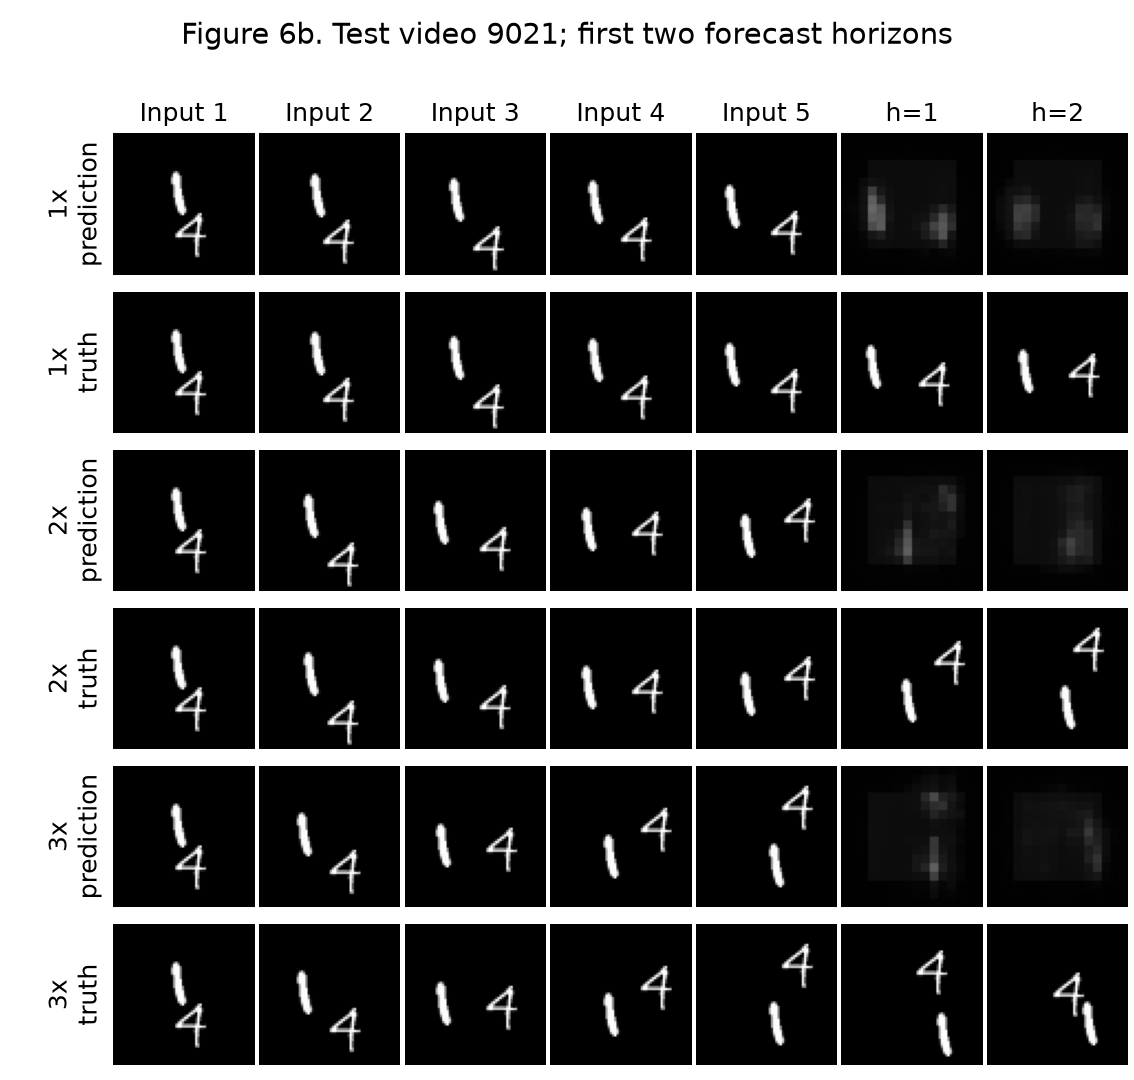

Figure 6(b). Final model on exactly test video 9021 from Figure 5, with the same speeds, input frames and first two forecast horizons.
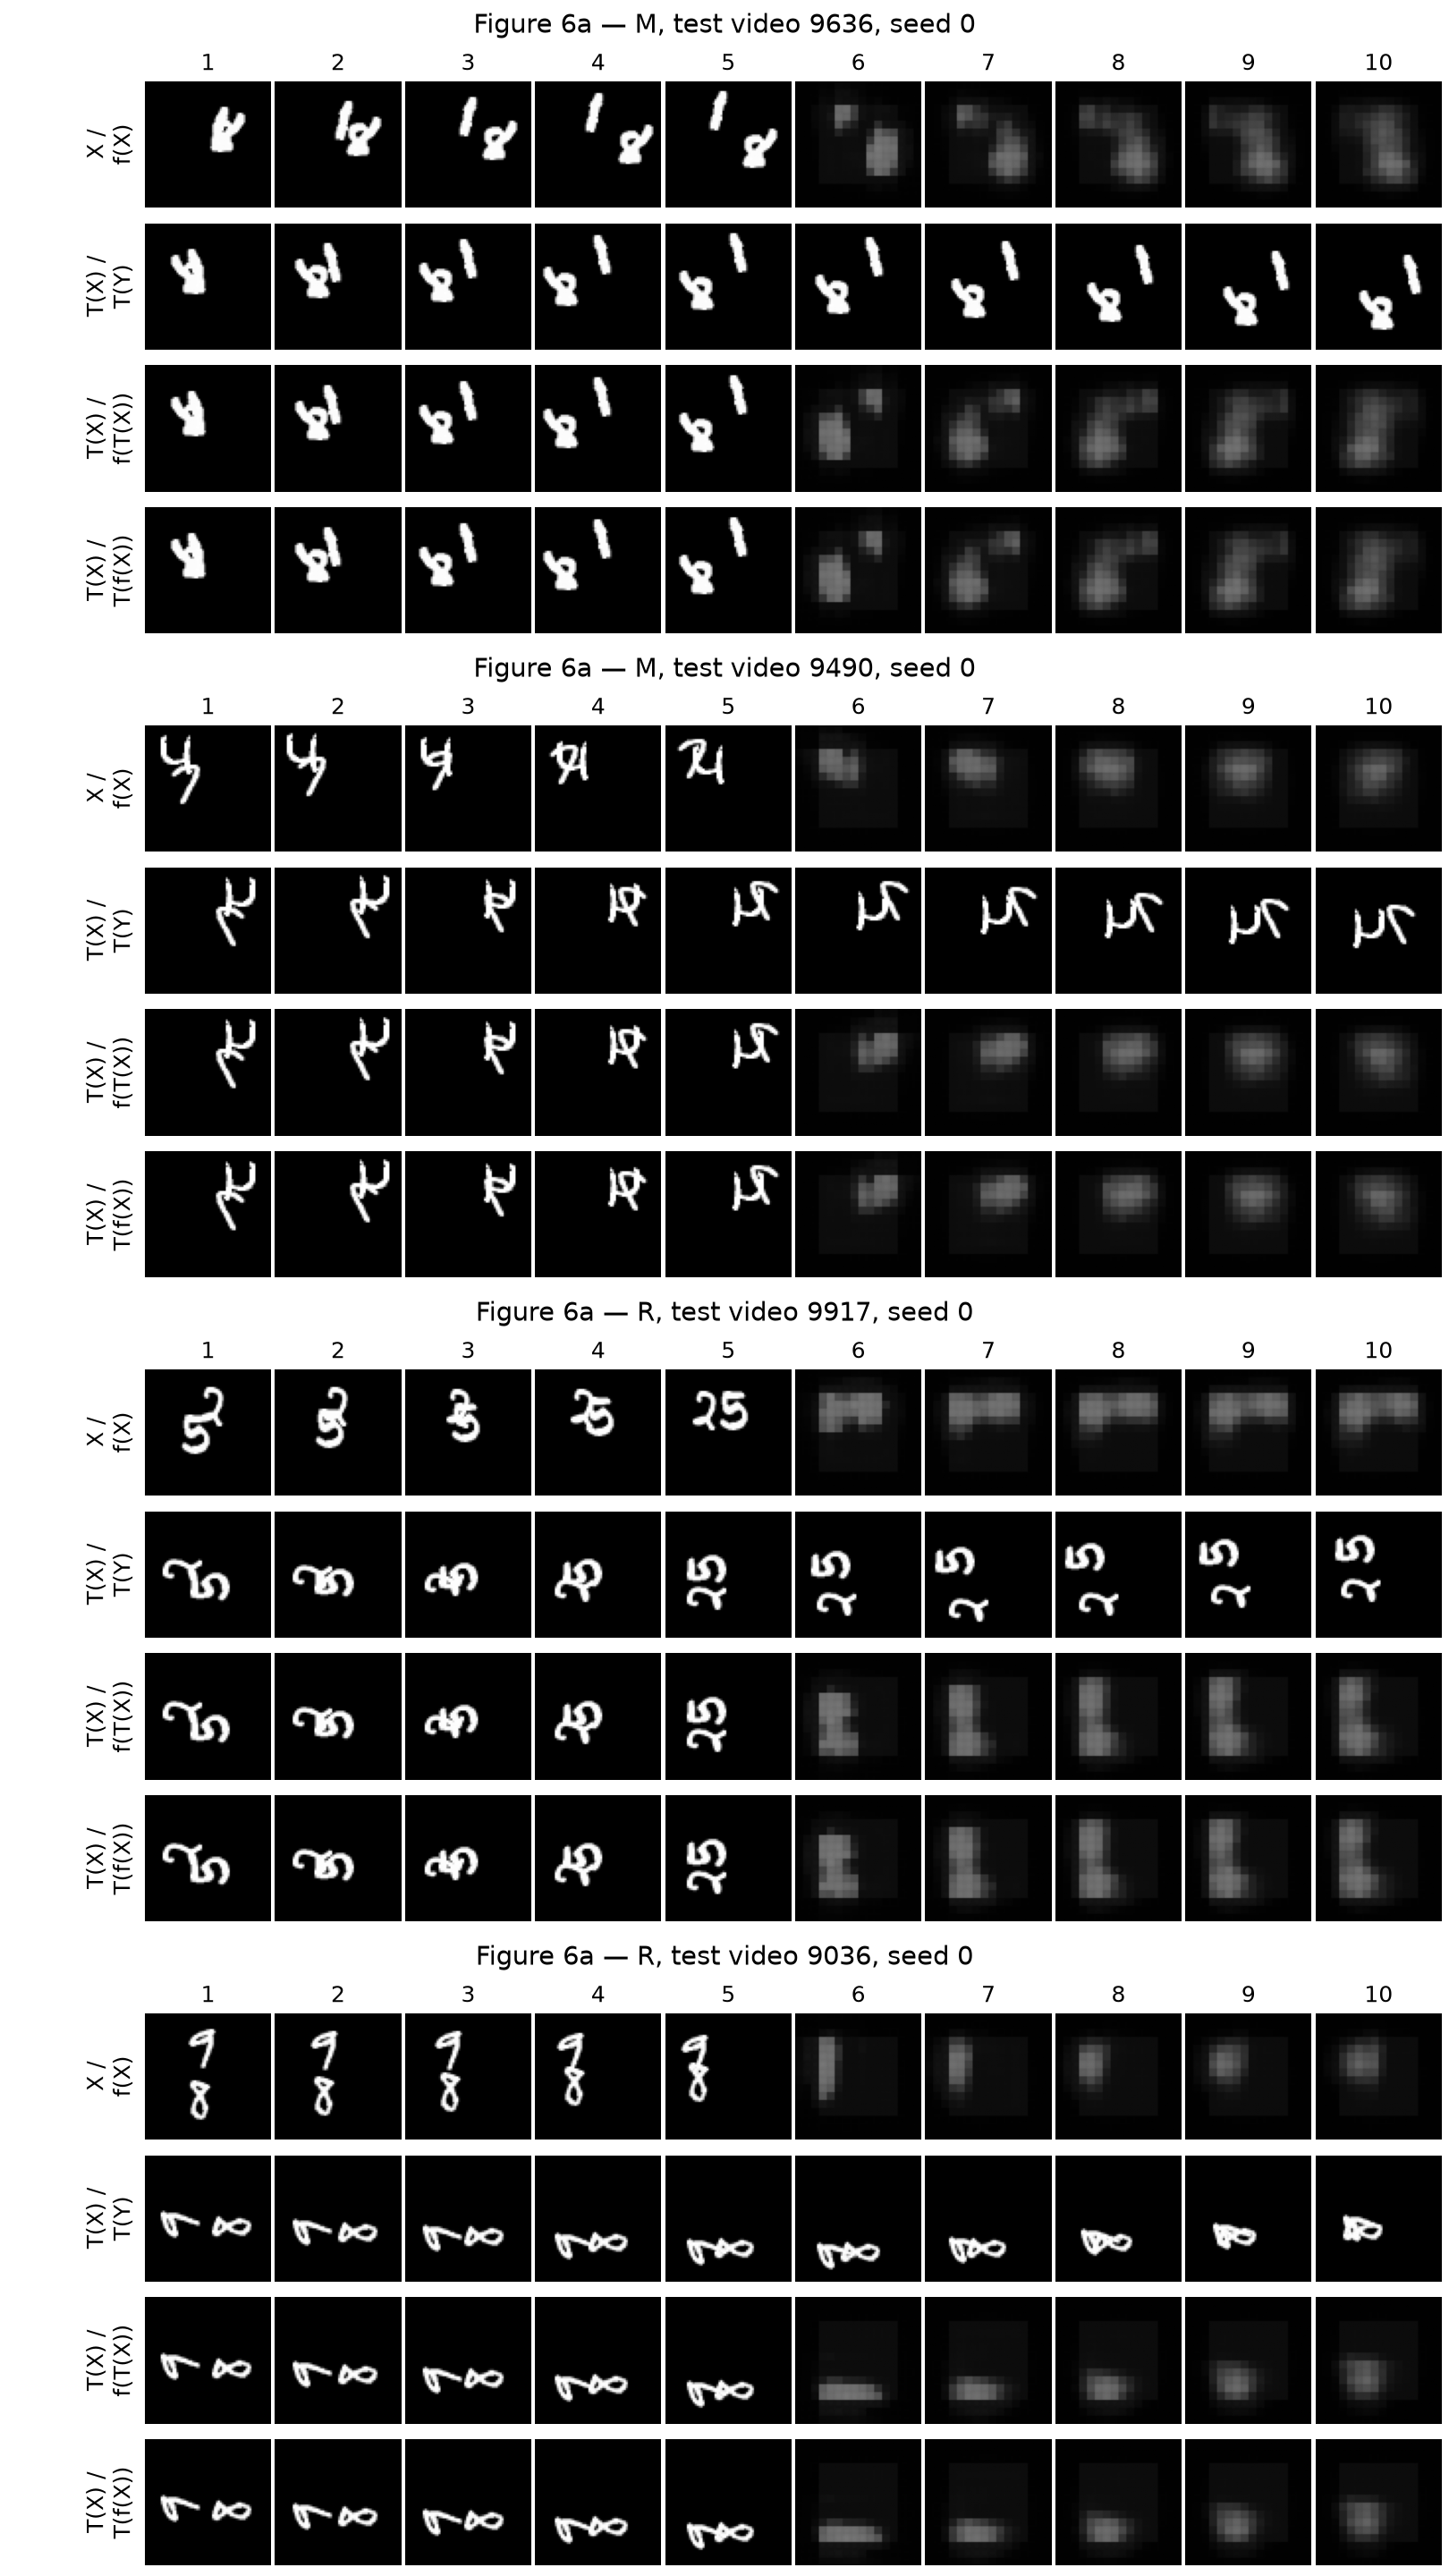

### Q2.15

B learns approximate symmetry: its Table 5 gaps are $C_M=0.00103$, $C_R=0.00132$. The wrapper enforces exact equivariance mathematically; Table 6 gives symmetrised B gaps 0.00e+00/0.00e+00 and symmetrised D gaps 0.00e+00/0.00e+00. This guarantees consistency, not accuracy. For B, wrapping changes original $E^{(5)}$ from 0.0229 to 0.0223, mirror error from 0.0229 to 0.0223, and rotation error from 0.0229 to 0.0223. For D, these changes are 0.0302 to 0.0302, 0.0302 to 0.0302, and 0.0306 to 0.0302.

Timed inference over 1,000 original clips is 2.32 seconds for B versus 12.1 for symmetrised B, and 2.07 for D versus 12.1 for symmetrised D. The eight passes plus transformations/averaging explain the increased cost; measured ratios need not equal exactly eight. The first timed call is included, so cold-start overhead also affects these totals. Averaging incompatible trajectories or phase-shifted digit locations can blur edges and hurt accuracy when the original orientation was already predicted better than the inverse-aligned alternatives. Here wrapping D worsened original-speed MSE by only 1.23e-07, an essentially negligible change hidden by Table 6's three-significant-figure rounding. Its diffuse predictions were already present in the underlying D. The wrapper requires no additional training or trainable parameters.

### Q2.16

The final model does not get test video 9917's rotated future right. Figure 6(a)'s rows 3 and 4 now coincide, removing A's disagreement between the two rotation routes. Both instead show a diffuse, nearly stationary L-shaped foreground mass instead of the two recognizable digits in row 2. Group averaging fixed consistency, while the underlying speed-trained D did not repair this case's digit separation, shape or motion. Table 5 also provides no accuracy advantage for D over C, so this case cannot be presented as evidence that the larger reach fixed the original motion failure. The exact row-3/row-4 agreement is fixed by group averaging; any gain in fast-motion accuracy is attributable to the learned underlying D and its training only through the controlled comparisons in Table 5, not to an increase in reach caused by the wrapper.

### Q2.17 — final verdict (under 150 words)

Exact symmetry is established; robust motion learning is not. At 3x the final model's $E^{(2)}$ is 0.0340, versus Blank 0.0426 and Copy-last 0.0703; at 1x its $E^{(5)}$ is 0.0302. Those gains show useful predictive information, but Figure 6's blurred, weakly moving foreground does not demonstrate correct object tracking. C's improvement over A supports learning from broader motion exposure; D's larger reach brings no measured accuracy gain over C. A skeptic needs both seeds, per-horizon errors and the same-video true-versus-predicted trajectories alongside consistency. The wrapper guarantees agreement between transformed routes, not correct physics. One unpassed test is transfer to unfamiliar shapes or more than two objects at held-out speeds. These experiments therefore support partial predictive learning, not a general motion simulator.